# Skin Image Classification: Accuracy, Uncertainty, and Human Review
**A student portfolio study of data quality and a selective classification workflow**

**Question:** Can image features distinguish the four supplied labels, and what happens to classification errors and review workload when the model defers uncertain cases?

**Decision context:** A hypothetical research-image review team wants assistance organizing labeled images. I compare simple baselines with transfer learning, then test a validation-selected deferral policy. This project measures agreement with supplied labels, not clinical diagnostic accuracy. It does not establish that any image is disease-free, recommend treatment, or assign medical urgency.

The distinctive contribution is the **audit before modeling**: repeated images, conflicting labels, and stock-style control images can make a seemingly impressive classifier misleading. All numerical conclusions below are calculated from this run.

**Roadmap:** provenance → file and duplicate audit → independent image groups → model comparison → calibration → review policy → untouched test evaluation → recommendation.

## 1. Reproduce the analysis
Install the adjacent `requirements.txt` in a Python environment with Jupyter, then run all cells in order. The dataset is pinned to Kaggle version 1. Set `SKIN_DATA_ROOT` to an already extracted dataset to avoid downloading it again. Otherwise KaggleHub downloads the versioned dataset; authentication may be required by Kaggle in some environments.

Sources: [Kaggle data card](https://www.kaggle.com/datasets/gupiii/infectious-skin-disease-dataset), [curator repository](https://github.com/lutfi015/skin-disease), [MobileNetV3 pretrained model](https://docs.pytorch.org/vision/stable/models/generated/torchvision.models.mobilenet_v3_small.html).

**Attribution:** Lutfi Farhan Prayoga (2026), *Infectious Skin Disease Dataset & Classification using Hybrid MobileNetV2-Xception with CLAHE Image Enhancement*, Universitas Airlangga. The Kaggle card lists CC BY 4.0 and identifies the University of Jammu Monkeypox Images Dataset and MSID as upstream sources. I have not independently established original image permissions, consent, expert label verification, or patient identities. Download instructions are provided; raw photos are not redistributed with this project.

In [1]:
import os, sys, json, hashlib, random
from pathlib import Path
from importlib.metadata import version
from collections import Counter
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from PIL import Image, ImageOps, ImageFilter
import imagehash
from IPython.display import display, Markdown
from sklearn.model_selection import StratifiedGroupKFold, StratifiedKFold, GridSearchCV
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.linear_model import LogisticRegression
from sklearn.dummy import DummyClassifier
from sklearn.metrics import (accuracy_score, balanced_accuracy_score, f1_score,
    classification_report, confusion_matrix, ConfusionMatrixDisplay, log_loss)
from scipy.optimize import minimize_scalar
from scipy.special import softmax
import torch
from torch import nn
from torch.utils.data import Dataset, DataLoader
from torchvision.models import mobilenet_v3_small, MobileNet_V3_Small_Weights

SEED = 42
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
torch.set_num_threads(min(4, os.cpu_count() or 1))
sns.set_theme(style="whitegrid", palette="colorblind")
ARTIFACTS = Path("artifacts"); ARTIFACTS.mkdir(exist_ok=True)
packages = ["numpy", "pandas", "scipy", "scikit-learn", "matplotlib", "seaborn",
            "pillow", "ImageHash", "torch", "torchvision", "kagglehub"]
environment = {p: version(p) for p in packages}
print("Python", sys.version.split()[0]); display(pd.Series(environment, name="Version"))
(ARTIFACTS / "environment.json").write_text(json.dumps(environment, indent=2))
if os.environ.get("SKIN_DATA_ROOT"):
    DATA_ROOT = Path(os.environ["SKIN_DATA_ROOT"]).expanduser().resolve()
else:
    import kagglehub
    DATA_ROOT = Path(kagglehub.dataset_download("gupiii/infectious-skin-disease-dataset/versions/1"))
combined_candidates = sorted(DATA_ROOT.rglob("Dataset_Gabungan"))
if DATA_ROOT.name == "Dataset_Gabungan":
    raise ValueError("Provide the extraction root containing all dataset folders, not only the combined folder")
assert combined_candidates, "Expected Dataset_Gabungan directory not found"
COMBINED_ROOT = combined_candidates[0]
print("Pinned dataset: gupiii/infectious-skin-disease-dataset / version 1")

Python 3.14.4


numpy            2.5.4
pandas           3.1.1
scipy           1.18.1
scikit-learn     1.9.1
matplotlib      3.11.2
seaborn         0.13.2
pillow          13.0.0
ImageHash        4.3.2
torch           2.15.0
torchvision     0.29.2
kagglehub        1.0.3
Name: Version, dtype: str

Pinned dataset: gupiii/infectious-skin-disease-dataset / version 1


## 2. Audit the files before trusting the data card
The card states 1,429 combined images but lists class counts totaling 1,428. It also describes prepared split directories. I count the actual files rather than assuming either statement is correct. Source folders and the combined folder are alternate copies, not separate training examples.

The manifest records relative paths, byte hashes, decoded-pixel hashes, perceptual hashes, dimensions, color modes, EXIF field counts, brightness, contrast, and an edge-strength proxy. Brightness is **not** a skin-tone measure. Edge strength is a rough image property, not a validated blur or medical-quality score.

In [2]:
def inspect_image(path):
    rel = path.relative_to(DATA_ROOT)
    record = {"path": str(rel), "subset": rel.parts[-3], "label": path.parent.name,
              "bytes": path.stat().st_size, "sha256": hashlib.sha256(path.read_bytes()).hexdigest()}
    try:
        with Image.open(path) as raw:
            record.update(width=raw.width, height=raw.height, mode=raw.mode,
                          format=raw.format, exif_fields=len(raw.getexif()))
            im = ImageOps.exif_transpose(raw).convert("RGB")
            arr = np.asarray(im)
            small = im.convert("L").resize((128, 128))
            gray = np.asarray(small, dtype=float)
            record.update(readable=True,
                pixel_sha256=hashlib.sha256(str(im.size).encode() + arr.tobytes()).hexdigest(),
                phash=str(imagehash.phash(im)), brightness=float(gray.mean()),
                contrast=float(gray.std()),
                edge_strength=float(np.asarray(small.filter(ImageFilter.FIND_EDGES), dtype=float)[1:-1,1:-1].mean()))
    except Exception as error:
        record.update(readable=False, error=str(error))
    return record

all_files = sorted(p for p in DATA_ROOT.rglob("*") if p.is_file())
manifest = pd.DataFrame(inspect_image(p) for p in all_files)
manifest.to_csv(ARTIFACTS / "image_manifest.csv", index=False)
file_counts = pd.crosstab(manifest.subset, manifest.label)
display(file_counts)
print("Unreadable files:", int((~manifest.readable).sum()))
print("Prepared split folders present:", sorted(p.name for p in DATA_ROOT.rglob("Dataset_Split*")))
pool = manifest[(manifest.subset == "Dataset_Gabungan") & manifest.readable].copy().reset_index(drop=True)
assert set(pool.label) == {"Chickenpox", "Measles", "Monkeypox", "Normal"}
pool["source"] = pool.path.map(lambda p: "Dataset_1" if Path(p).name.startswith("ds1_") else
                                         "Dataset_2" if Path(p).name.startswith("ds2_") else "Unknown")
display(pool.groupby("label").size().rename("Combined images").to_frame())
display(pd.crosstab(pool.source, pool.width))
print("Unique byte hashes:", pool.sha256.nunique(), "of", len(pool))
print("Unique decoded images:", pool.pixel_sha256.nunique(), "of", len(pool))
print("Images with EXIF fields:", int(pool.exif_fields.gt(0).sum()))
display(pool[["width", "height", "brightness", "contrast", "edge_strength"]].describe().round(2))

label,Chickenpox,Measles,Monkeypox,Normal
subset,,,,
Dataset_1,100,80,264,215
Dataset_2,107,91,279,293
Dataset_Gabungan,207,171,543,508


Unreadable files: 0
Prepared split folders present: []


,Combined images
label,
Chickenpox,207
Measles,171
Monkeypox,543
Normal,508


width,224,256
source,,
Dataset_1,0,659
Dataset_2,770,0


Unique byte hashes: 1419 of 1429
Unique decoded images: 1419 of 1429
Images with EXIF fields: 0


,width,height,brightness,contrast,edge_strength
count,1429.00,1429.00,1429.00,1429.00,1429.00
mean,238.76,238.76,152.12,43.60,12.97
std,15.96,15.96,42.41,14.53,6.14
min,224.00,224.00,35.05,7.70,1.64
25%,224.00,224.00,122.39,33.26,8.60
50%,224.00,224.00,153.09,42.43,12.19
75%,256.00,256.00,183.25,53.59,15.78
max,256.00,256.00,241.25,88.04,42.42


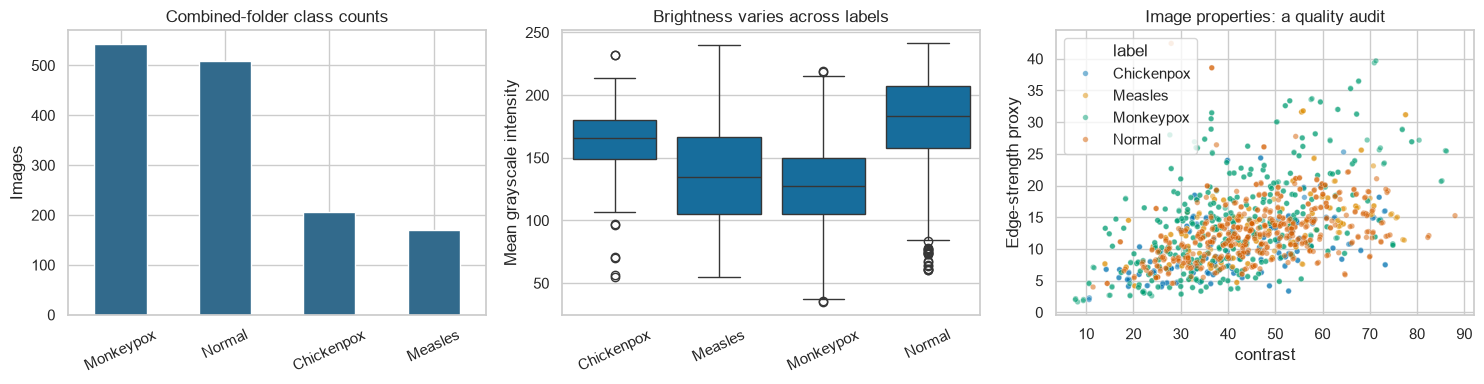

In [3]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
pool.label.value_counts().plot.bar(ax=axes[0], color="#326a8c")
axes[0].set(title="Combined-folder class counts", ylabel="Images", xlabel="")
axes[0].tick_params(axis="x", rotation=25)
sns.boxplot(data=pool, x="label", y="brightness", ax=axes[1])
axes[1].set(title="Brightness varies across labels", xlabel="", ylabel="Mean grayscale intensity")
axes[1].tick_params(axis="x", rotation=25)
sns.scatterplot(data=pool, x="contrast", y="edge_strength", hue="label", s=16, alpha=.5, ax=axes[2])
axes[2].set(title="Image properties: a quality audit", ylabel="Edge-strength proxy")
plt.tight_layout(); plt.show()

### What the initial audit changes
- The downloaded combined folder contains **1,429 readable RGB images**, including **171 Measles** images, rather than the 170 listed in the card. The accompanying source README gives yet another total (1,428).
- This release contains the two source folders and the combined folder; the prepared split directories mentioned in the card are absent.
- Source membership and original resolution are perfectly associated here: Dataset_1 images are 256×256, Dataset_2 images are 224×224. Both are resized for modeling, but other source signatures may remain.
- A local visual spot-check found lesion photos mixed with portraits and stock-style images in the Normal class. A classifier can exploit composition and backgrounds rather than skin findings. “Normal” below always means the supplied label, not verified health.
- Filenames identify source collections, not patients. There are no demographic annotations or patient-level identifiers available in this release. Patient independence, fairness, and clinical label validity cannot be established.

## 3. Detect duplicate families and conflicting labels
Byte hashes detect identical files; decoded-pixel hashes detect identical decoded images. Perceptual hashes identify candidate near-duplicates despite resizing or recompression. I join pairs with 64-bit pHash Hamming distance ≤4 into connected components. This is a conservative heuristic, not a patient-identification method or a complete duplicate detector; connected chains can group images farther apart than the pairwise cutoff.

The cutoff is fixed before modeling. A visual spot-check confirmed repeated versions and the cross-label conflict, but not every candidate pair was manually reviewed. I exclude components containing conflicting labels and randomly retain one representative per remaining component, using a fixed seed. This avoids counting multiple near-identical views as independent successes.

In [4]:
parents = list(range(len(pool)))
def find(i):
    while parents[i] != i:
        parents[i] = parents[parents[i]]
        i = parents[i]
    return i

def union(i, j):
    a, b = find(i), find(j)
    if a != b:
        parents[max(a,b)] = min(a,b)

for _, indices in pool.groupby("pixel_sha256").groups.items():
    indices = list(indices)
    for j in indices[1:]: union(indices[0], j)
hashes = [int(h, 16) for h in pool.phash]
pairs = []
for i in range(len(pool)):
    for j in range(i+1, len(pool)):
        distance = (hashes[i] ^ hashes[j]).bit_count()
        if distance <= 4:
            union(i, j)
            pairs.append({"path_a": pool.path[i], "path_b": pool.path[j],
                "label_a": pool.label[i], "label_b": pool.label[j],
                "phash_distance": distance,
                "same_pixels": pool.pixel_sha256[i] == pool.pixel_sha256[j]})
near_pairs = pd.DataFrame(pairs)
near_pairs.to_csv(ARTIFACTS / "near_duplicate_candidates.csv", index=False)
pool["duplicate_group"] = [f"g{find(i):04d}" for i in range(len(pool))]
group_label_counts = pool.groupby("duplicate_group").label.nunique()
conflict_groups = set(group_label_counts[group_label_counts > 1].index)
conflicts = pool[pool.duplicate_group.isin(conflict_groups)].copy()
conflicts.to_csv(ARTIFACTS / "excluded_label_conflicts.csv", index=False)
clean_pool = pool[~pool.duplicate_group.isin(conflict_groups)].copy()
# A deterministic random representative avoids systematically preferring the first source.
representatives = (clean_pool.sample(frac=1, random_state=SEED)
                   .drop_duplicates("duplicate_group").sort_values("path").reset_index(drop=True))
print("Candidate near-duplicate pairs:", len(near_pairs))
print("Perceptual/pixel groups:", pool.duplicate_group.nunique())
print("Conflicting-label groups:", len(conflict_groups), "| excluded images:", len(conflicts))
print("Representatives retained:", len(representatives))
display(conflicts[["path", "label", "duplicate_group"]])
display(pd.crosstab(representatives.label, representatives.source))
assert representatives.duplicate_group.is_unique
assert representatives.pixel_sha256.is_unique

Candidate near-duplicate pairs: 735
Perceptual/pixel groups: 749
Conflicting-label groups: 1 | excluded images: 4
Representatives retained: 748


,path,label,duplicate_group
87,Dataset_Gabungan/Chickenpox/ds1_ChickenPox_88.jpg,Chickenpox,g0087
201,Dataset_Gabungan/Chickenpox/ds2_chickenpox94.png,Chickenpox,g0087
623,Dataset_Gabungan/Monkeypox/ds1_MonkeyPox_82.jpg,Monkeypox,g0087
904,Dataset_Gabungan/Monkeypox/ds2_monkeypox84.png,Monkeypox,g0087


source,Dataset_1,Dataset_2
label,,
Chickenpox,55,46
Measles,33,54
Monkeypox,132,138
Normal,104,186


**Audit decision:** Proceed with a limited portfolio benchmark, not a deployable diagnostic system. The label-conflict images are excluded rather than relabeled: visual inspection is not medical adjudication. All remaining labels are taken as provided and may still be wrong. The reduced sample size is a more defensible measure of evidence than counting repeated variants as new observations.

## 4. Lock development, calibration, policy, and test partitions
Ten stratified group folds define approximately **60% training, 10% calibration, 10% policy validation, and 20% final test**. Assignments are fixed before feature fitting. There is one representative per duplicate group; the group assertions document that duplicate families do not cross partitions. This does not guarantee independence of unseen patient identities or remove all visual similarity.

Model parameters are selected with training-only CV. Calibration fits one scalar temperature on its own subset. The review threshold uses only policy-validation labels. Final test labels are used once to evaluate the locked models and policy. The primary model is prespecified as logistic regression on frozen pretrained embeddings; it is not chosen from test outcomes.

In [5]:
encoder = LabelEncoder()
y = encoder.fit_transform(representatives.label)
classes = encoder.classes_
folds = np.full(len(representatives), -1)
splitter = StratifiedGroupKFold(n_splits=10, shuffle=True, random_state=SEED)
for fold, (_, idx) in enumerate(splitter.split(representatives, y, representatives.duplicate_group)):
    folds[idx] = fold
roles = np.where(folds < 2, "test", np.where(folds == 2, "calibration", np.where(folds == 3, "policy", "train")))
representatives["partition"] = roles
representatives["encoded_label"] = y
idx = {role: np.flatnonzero(roles == role) for role in ["train", "calibration", "policy", "test"]}
for a in idx:
    assert set(np.unique(y[idx[a]])) == set(range(len(classes))), f"Missing class in {a}"
    for b in idx:
        if a != b:
            assert set(representatives.iloc[idx[a]].duplicate_group).isdisjoint(representatives.iloc[idx[b]].duplicate_group)
representatives.to_csv(ARTIFACTS / "split_manifest.csv", index=False)
display(pd.crosstab(representatives.label, representatives.partition))
manifest_fingerprint = hashlib.sha256(representatives[["path","pixel_sha256","partition"]].to_csv(index=False).encode()).hexdigest()
print("Split-manifest fingerprint:", manifest_fingerprint)

partition,calibration,policy,test,train
label,,,,
Chickenpox,11,10,20,60
Measles,8,9,18,52
Monkeypox,27,27,54,162
Normal,29,29,58,174


Split-manifest fingerprint: 7d7ec9276a7e0137d7ecfc137f300e88fc1a1c9f17e6f92fb2f93edc0326e1e2


## 5. Build simple and transferred image representations
**Baseline 1:** majority-class prediction. **Baseline 2:** normalized per-channel RGB histograms with logistic regression. **Primary model:** ImageNet-pretrained MobileNetV3-Small frozen embeddings with a regularized logistic head. The histogram baseline tests whether simple color statistics already explain much of the label separation.

The pretrained encoder is never fitted on this dataset. Images use the pretrained weights' normalization and crop transforms. I do not fine-tune the network or apply training augmentation in this first experiment: the goal is a compact, reproducible benchmark that exposes data limitations. A future fine-tuning comparison would require a fresh evaluation plan.

In [6]:
weights = MobileNet_V3_Small_Weights.IMAGENET1K_V1
backbone = mobilenet_v3_small(weights=weights)
backbone.classifier = nn.Identity()
backbone.eval()
for parameter in backbone.parameters(): parameter.requires_grad_(False)
transform = weights.transforms()

class ImageRows(Dataset):
    def __init__(self, rows): self.paths = rows.path.tolist()
    def __len__(self): return len(self.paths)
    def __getitem__(self, i):
        with Image.open(DATA_ROOT / self.paths[i]) as raw:
            return transform(ImageOps.exif_transpose(raw).convert("RGB"))

# Cache is keyed by data order, pixel hashes, encoder identity and torchvision version.
feature_key = hashlib.sha256((representatives[["path","pixel_sha256"]].to_csv(index=False)
    + "mobilenet_v3_small_IMAGENET1K_V1_" + version("torchvision")).encode()).hexdigest()
feature_cache = ARTIFACTS / f"embeddings_{feature_key[:16]}.npz"
if feature_cache.exists():
    features = np.load(feature_cache)["features"]
else:
    batches = []
    loader = DataLoader(ImageRows(representatives), batch_size=32, shuffle=False, num_workers=0)
    with torch.inference_mode():
        for batch in loader:
            batches.append(backbone(batch).cpu().numpy())
    features = np.concatenate(batches)
    np.savez_compressed(feature_cache, features=features)

histograms = []
for rel in representatives.path:
    with Image.open(DATA_ROOT / rel) as raw:
        rgb = np.asarray(ImageOps.exif_transpose(raw).convert("RGB").resize((128,128)))
        vector = np.concatenate([np.histogram(rgb[:,:,ch], bins=16, range=(0,256))[0] for ch in range(3)]).astype(float)
        histograms.append(vector / vector.sum())
histograms = np.asarray(histograms)
assert features.shape[0] == len(y) and np.isfinite(features).all()
print("Frozen embedding dimensions:", features.shape, "| RGB histogram dimensions:", histograms.shape)

Frozen embedding dimensions: (748, 576) | RGB histogram dimensions: (748, 48)


## 6. Compare models within training data
Three-fold stratified CV selects regularization from C={0.01, 0.1, 1, 10} using macro-F1. Standardization is fitted inside the pipeline on each training fold. Class weights are balanced to keep minority labels relevant. CV scores used for hyperparameter selection are development estimates, not independent final performance estimates.

Accuracy weights frequent classes more heavily; macro-F1 treats each class equally, and balanced accuracy averages class recall. No metric here establishes real-world sensitivity or specificity for these conditions.

In [7]:
train_i = idx["train"]
cv = StratifiedKFold(n_splits=3, shuffle=True, random_state=SEED)
model_specs = {"RGB histogram + logistic": histograms, "Frozen MobileNet + logistic": features}
searches = {}; cv_rows = []
for name, matrix in model_specs.items():
    estimator = make_pipeline(StandardScaler(), LogisticRegression(max_iter=3000, class_weight="balanced", random_state=SEED))
    search = GridSearchCV(estimator, {"logisticregression__C": [.01, .1, 1., 10.]},
                         scoring="f1_macro", cv=cv, n_jobs=1, error_score="raise")
    search.fit(matrix[train_i], y[train_i])
    searches[name] = search
    cv_rows.append({"model":name, "selected_C":search.best_params_["logisticregression__C"],
                    "training_CV_macro_F1":search.best_score_})
display(pd.DataFrame(cv_rows).set_index("model").round(3))
primary = searches["Frozen MobileNet + logistic"].best_estimator_
baseline = DummyClassifier(strategy="most_frequent").fit(features[train_i], y[train_i])

,selected_C,training_CV_macro_F1
model,,
RGB histogram + logistic,0.1,0.453
Frozen MobileNet + logistic,1.0,0.786


## 7. Calibrate confidence without using test labels
Raw classifier confidence can be misleading. Temperature scaling fits one positive scalar to multiclass logits using the calibration subset and log loss. It preserves predicted class rankings. A small calibration sample makes this estimate uncertain; it is not proof of reliable probabilities on different sources or patients.

I fix the permitted temperature range in advance. Calibration and policy subsets are kept separate to reduce reuse of labels for multiple choices.

In [8]:
cal_i = idx["calibration"]
cal_logits = primary.decision_function(features[cal_i])
def fit_temperature(logits, truth):
    objective = lambda log_t: log_loss(truth, softmax(logits / np.exp(log_t), axis=1), labels=np.arange(len(classes)))
    result = minimize_scalar(objective, bounds=(np.log(.1), np.log(10.)), method="bounded")
    assert result.success
    return float(np.exp(result.x))
temperature = fit_temperature(cal_logits, y[cal_i])
print(f"Fitted temperature: {temperature:.3f}")
print(f"Calibration log loss before: {log_loss(y[cal_i], softmax(cal_logits,axis=1)):.3f}")
print(f"Calibration log loss after:  {log_loss(y[cal_i], softmax(cal_logits/temperature,axis=1)):.3f}")
print("These calibration values are in-sample fitting diagnostics, not final estimates.")

Fitted temperature: 1.956
Calibration log loss before: 0.619
Calibration log loss after:  0.490
These calibration values are in-sample fitting diagnostics, not final estimates.


## 8. Select a human-review policy on policy-validation data
**Illustrative policy:** accept a model label only when its calibrated maximum probability exceeds a threshold; otherwise defer to human review. The target is at least **90% observed label accuracy among accepted validation images**, with at least **20 accepted examples**. Among thresholds meeting those criteria, choose the one with the greatest coverage. If none qualifies, defer every image.

These are project assumptions, not clinical safety requirements. The target uses a point estimate on a small sample, not a statistical guarantee. Threshold selection itself can be optimistic; its stability is assessed only on the final test set. A model can be confidently wrong. “Deferred” never means “healthy,” and human reviewers are not assumed to be error-free.

Validation target met; fixed threshold evaluated below


,Locked validation policy
threshold,0.5481
accepted,67.0000
deferred,8.0000
coverage,0.8933
accepted_errors,6.0000
accepted_accuracy,0.9104


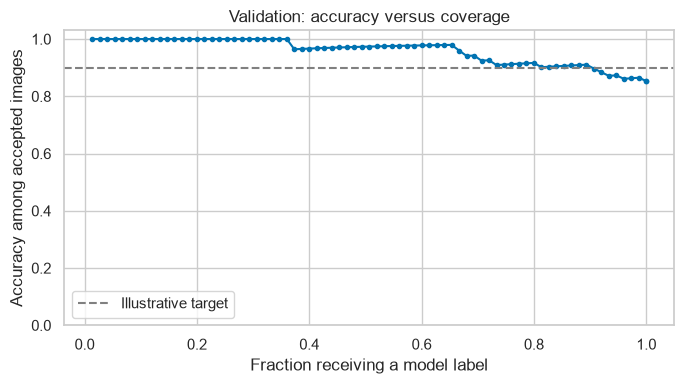

In [9]:
policy_i = idx["policy"]
policy_prob = softmax(primary.decision_function(features[policy_i]) / temperature, axis=1)
policy_conf = policy_prob.max(axis=1)
policy_pred = policy_prob.argmax(axis=1)
TARGET_ACCURACY = .90
MIN_ACCEPTED = 20

def policy_summary(truth, pred, confidence, threshold):
    accepted = confidence >= threshold
    n = int(accepted.sum())
    errors = int((pred[accepted] != truth[accepted]).sum())
    return {"threshold":float(threshold), "accepted":n, "deferred":int(len(truth)-n),
            "coverage":float(accepted.mean()), "accepted_errors":errors,
            "accepted_accuracy":float(1-errors/n) if n else np.nan}

policy_curve = pd.DataFrame(policy_summary(y[policy_i], policy_pred, policy_conf, threshold)
    for threshold in np.unique(np.r_[0., policy_conf, np.nextafter(1.,2.)]))
qualifying = policy_curve[(policy_curve.accepted >= MIN_ACCEPTED) & (policy_curve.accepted_accuracy >= TARGET_ACCURACY)]
if len(qualifying):
    selected_policy = qualifying.sort_values(["coverage","threshold"], ascending=[False,True]).iloc[0]
    threshold = float(selected_policy.threshold)
    policy_status = "Validation target met; fixed threshold evaluated below"
else:
    threshold = float(np.nextafter(1.,2.))
    selected_policy = pd.Series(policy_summary(y[policy_i], policy_pred, policy_conf, threshold))
    policy_status = "No qualifying validation policy; defer all images"
print(policy_status)
display(selected_policy.to_frame("Locked validation policy").round(4))
policy_curve.to_csv(ARTIFACTS / "policy_validation_curve.csv", index=False)
fig, ax = plt.subplots(figsize=(7,4))
ax.plot(policy_curve.coverage, policy_curve.accepted_accuracy, marker=".")
ax.axhline(TARGET_ACCURACY, color="gray", linestyle="--", label="Illustrative target")
ax.set(xlabel="Fraction receiving a model label", ylabel="Accuracy among accepted images",
       title="Validation: accuracy versus coverage", ylim=(0,1.03))
ax.legend(); plt.tight_layout(); plt.show()

## 9. Open the final test set: classification and review workload
The following results evaluate the already fixed models and review policy. The threshold is not revised after examining these outcomes. Test curves and error tables are descriptive diagnostics only. Accuracy among accepted images must be read together with coverage and per-class deferral: a system can look accurate by declining most difficult cases.

,accuracy,balanced_accuracy,macro_F1
model,,,
Majority baseline,0.387,0.250,0.139
RGB histogram + logistic,0.513,0.469,0.463
Frozen MobileNet + logistic,0.867,0.834,0.817


              precision    recall  f1-score   support

  Chickenpox       0.64      0.70      0.67        20
     Measles       0.68      0.83      0.75        18
   Monkeypox       0.94      0.87      0.90        54
      Normal       0.96      0.93      0.95        58

    accuracy                           0.87       150
   macro avg       0.81      0.83      0.82       150
weighted avg       0.88      0.87      0.87       150



,Final test policy
threshold,0.5481
accepted,134.0000
deferred,16.0000
coverage,0.8933
accepted_errors,13.0000
accepted_accuracy,0.9030


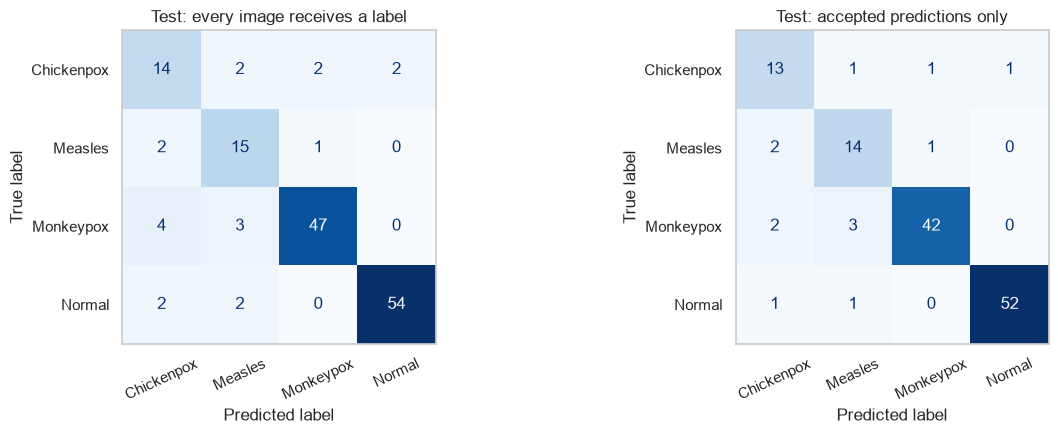

In [10]:
test_i = idx["test"]
test_truth = y[test_i]
test_logits = primary.decision_function(features[test_i])
test_prob = softmax(test_logits / temperature, axis=1)
test_pred = test_prob.argmax(axis=1)
test_conf = test_prob.max(axis=1)
accepted = test_conf >= threshold

model_test_rows = []
for name, pred in [("Majority baseline", baseline.predict(features[test_i])),
                   ("RGB histogram + logistic", searches["RGB histogram + logistic"].predict(histograms[test_i])),
                   ("Frozen MobileNet + logistic", test_pred)]:
    model_test_rows.append({"model":name, "accuracy":accuracy_score(test_truth,pred),
        "balanced_accuracy":balanced_accuracy_score(test_truth,pred), "macro_F1":f1_score(test_truth,pred,average="macro")})
test_comparison = pd.DataFrame(model_test_rows).set_index("model")
display(test_comparison.round(3))
print(classification_report(test_truth, test_pred, labels=np.arange(len(classes)), target_names=classes, zero_division=0))
test_policy = policy_summary(test_truth, test_pred, test_conf, threshold)
display(pd.Series(test_policy, name="Final test policy").to_frame().round(4))

fig, axes = plt.subplots(1,2,figsize=(13,4.5))
ConfusionMatrixDisplay.from_predictions(test_truth, test_pred, labels=np.arange(len(classes)),
    display_labels=classes, cmap="Blues", colorbar=False, ax=axes[0], xticks_rotation=25)
axes[0].set_title("Test: every image receives a label"); axes[0].grid(False)
if accepted.any():
    ConfusionMatrixDisplay.from_predictions(test_truth[accepted], test_pred[accepted], labels=np.arange(len(classes)),
        display_labels=classes, cmap="Blues", colorbar=False, ax=axes[1], xticks_rotation=25)
    axes[1].grid(False); axes[1].set_title("Test: accepted predictions only")
else:
    axes[1].text(.5,.5,"All test images deferred",ha="center",va="center"); axes[1].axis("off")
plt.tight_layout(); plt.show()

In [11]:
# Multiclass Brier score is the unscaled sum of squared class-probability errors (range 0–2).
def multiclass_brier(truth, probs):
    return float(np.mean(np.sum((probs - np.eye(len(classes))[truth])**2, axis=1)))
raw_test_prob = softmax(test_logits, axis=1)
calibration_test = pd.DataFrame([
    {"probabilities":"Raw", "log_loss":log_loss(test_truth,raw_test_prob), "Brier":multiclass_brier(test_truth,raw_test_prob)},
    {"probabilities":"Temperature scaled", "log_loss":log_loss(test_truth,test_prob), "Brier":multiclass_brier(test_truth,test_prob)}])
display(calibration_test.round(3))

predictions = representatives.iloc[test_i][["path","label","source","duplicate_group"]].copy()
predictions["prediction"] = encoder.inverse_transform(test_pred)
predictions["confidence"] = test_conf
predictions["accepted"] = accepted
predictions["correct"] = test_pred == test_truth
predictions.to_csv(ARTIFACTS / "test_predictions.csv", index=False)
# Reviewers see model suggestions but not benchmark labels; no reviewer outcomes are invented.
review_queue = predictions.loc[~predictions.accepted, ["path","prediction","confidence"]].copy()
review_queue = review_queue.rename(columns={"prediction":"model_suggestion"}).sort_values("confidence")
review_queue["review_status"] = "pending"
review_queue["reviewer_label"] = ""
review_queue["review_notes"] = ""
review_queue.to_csv(ARTIFACTS / "human_review_queue.csv", index=False)
routing_table = pd.crosstab(predictions.correct.map({True:"Correct model label",False:"Incorrect model label"}),
                            predictions.accepted.map({True:"Accepted",False:"Deferred"}))
print("Retrospective routing outcomes (human decisions have not been observed):")
display(routing_table)
all_errors = int((~predictions.correct).sum())
deferred_errors = int((~predictions.correct & ~predictions.accepted).sum())
error_capture = deferred_errors / all_errors if all_errors else np.nan
print(f"Deferral captured {deferred_errors} of {all_errors} model errors; it does not resolve them automatically.")
print(f"Pending human-review queue exported: {len(review_queue)} images")
class_review = predictions.groupby("label").agg(images=("correct","size"),
    full_accuracy=("correct","mean"), accepted=("accepted","sum"))
class_review["coverage"] = class_review.accepted / class_review.images
accepted_accuracy = predictions[predictions.accepted].groupby("label").correct.mean()
class_review["accepted_accuracy"] = accepted_accuracy
print("Class-specific workload; NaN means no accepted examples:")
display(class_review.round(3))
print("Source-specific descriptive results (not an independent source holdout):")
display(predictions.groupby("source").agg(images=("correct","size"), accuracy=("correct","mean"), coverage=("accepted","mean")).round(3))
print("Most confident errors (no raw photos redistributed):")
display(predictions[~predictions.correct].sort_values("confidence",ascending=False).head(10))

,probabilities,log_loss,Brier
0,Raw,0.412,0.208
1,Temperature scaled,0.380,0.203


Retrospective routing outcomes (human decisions have not been observed):


accepted,Accepted,Deferred
correct,,
Correct model label,121,9
Incorrect model label,13,7


Deferral captured 7 of 20 model errors; it does not resolve them automatically.
Pending human-review queue exported: 16 images
Class-specific workload; NaN means no accepted examples:


,images,full_accuracy,accepted,coverage,accepted_accuracy
label,,,,,
Chickenpox,20,0.700,16,0.800,0.812
Measles,18,0.833,17,0.944,0.824
Monkeypox,54,0.870,47,0.870,0.894
Normal,58,0.931,54,0.931,0.963


Source-specific descriptive results (not an independent source holdout):


,images,accuracy,coverage
source,,,
Dataset_1,61,0.852,0.836
Dataset_2,89,0.876,0.933


Most confident errors (no raw photos redistributed):


,path,label,source,duplicate_group,prediction,confidence,accepted,correct
235,Dataset_Gabungan/Monkeypox/ds1_MonkeyPox_190.jpg,Monkeypox,Dataset_1,g0479,Measles,0.927088,True,False
17,Dataset_Gabungan/Chickenpox/ds1_ChickenPox_46.jpg,Chickenpox,Dataset_1,g0041,Monkeypox,0.899251,True,False
152,Dataset_Gabungan/Measles/ds2_measles33.png,Measles,Dataset_2,g0231,Chickenpox,0.846241,True,False
611,Dataset_Gabungan/Normal/ds2_normal166.png,Normal,Dataset_2,g0947,Measles,0.764398,True,False
605,Dataset_Gabungan/Normal/ds2_normal154.png,Normal,Dataset_2,g0934,Chickenpox,0.750434,True,False
374,Dataset_Gabungan/Monkeypox/ds2_monkeypox191.png,Monkeypox,Dataset_2,g0468,Measles,0.743533,True,False
149,Dataset_Gabungan/Measles/ds2_measles30.png,Measles,Dataset_2,g0227,Monkeypox,0.696449,True,False
116,Dataset_Gabungan/Measles/ds1_Measles_43.jpg,Measles,Dataset_1,g0244,Chickenpox,0.696263,True,False
280,Dataset_Gabungan/Monkeypox/ds1_MonkeyPox_262.jpg,Monkeypox,Dataset_1,g0559,Chickenpox,0.585537,True,False
31,Dataset_Gabungan/Chickenpox/ds1_ChickenPox_62.jpg,Chickenpox,Dataset_1,g0059,Normal,0.576595,True,False


### Quantify uncertainty without implying a guarantee
Wilson 95% intervals summarize binomial sampling uncertainty for full accuracy and accepted-only accuracy. They assume independent observations. Deduplication helps with obvious image repeats, but unknown patient and source dependencies, threshold selection, and dataset bias are not included. The intervals do not establish clinical safety.

In [12]:
def wilson(successes, n, z=1.959963984540054):
    if n == 0: return (np.nan,np.nan)
    p = successes/n; d = 1+z*z/n
    c = (p+z*z/(2*n))/d
    h = z*np.sqrt(p*(1-p)/n+z*z/(4*n*n))/d
    return float(c-h),float(c+h)
full_ci = wilson(int((test_pred==test_truth).sum()), len(test_truth))
accepted_ci = wilson(int(((test_pred==test_truth)&accepted).sum()), int(accepted.sum()))
print("Full test accuracy Wilson interval:", np.round(full_ci,3))
print("Accepted accuracy Wilson interval:", np.round(accepted_ci,3))

# Workload scenario: a direct scaling of this test distribution, not a business forecast.
scenario = pd.Series({
    "model_labeled_per_1000":1000*test_policy["coverage"],
    "human_review_per_1000":1000*(1-test_policy["coverage"]),
    "incorrect_model_labels_per_1000":1000*test_policy["accepted_errors"]/len(test_truth)},
    name="Illustrative test-mix workload")
display(scenario.round(1).to_frame())

Full test accuracy Wilson interval: [0.803 0.912]
Accepted accuracy Wilson interval: [0.841 0.942]


,Illustrative test-mix workload
model_labeled_per_1000,893.3
human_review_per_1000,106.7
incorrect_model_labels_per_1000,86.7


## 10. Conclusions: what would I recommend to the review team?
The summary below is generated from this run. It reports limitations and target failures rather than changing the threshold to improve the final test result.

In [13]:
primary_results = test_comparison.loc["Frozen MobileNet + logistic"]
accept_text = (f"{test_policy['accepted_accuracy']:.1%} (Wilson 95% interval {accepted_ci[0]:.1%}–{accepted_ci[1]:.1%})"
               if test_policy["accepted"] else "undefined because no images were accepted")
meets_test_target = bool(test_policy["accepted"] and test_policy["accepted_accuracy"] >= TARGET_ACCURACY)
summary = f"""
**Dataset audit:** {len(pool):,} combined images became **{len(representatives):,} representative image groups** after excluding {len(conflicts)} conflicting-label images. Near-duplicate detection found {len(near_pairs)} candidate pairs. These are heuristic image groups, not verified independent patients.

**Classification:** Frozen MobileNet embeddings with logistic regression achieved test **macro-F1 {primary_results['macro_F1']:.3f}**, balanced accuracy **{primary_results['balanced_accuracy']:.3f}**, and accuracy **{primary_results['accuracy']:.1%}**. The histogram baseline's macro-F1 was **{test_comparison.loc['RGB histogram + logistic','macro_F1']:.3f}**. This comparison describes agreement with these supplied labels, not diagnostic validity.

**Human-review policy:** At the validation-selected threshold **{threshold:.3f}**, **{test_policy['accepted']} of {len(test_truth)}** test images received model labels and **{test_policy['deferred']}** were deferred. Accepted-only accuracy was **{accept_text}**, with **{test_policy['accepted_errors']} incorrect accepted labels**. The illustrative 90% point-accuracy target **{'was met' if meets_test_target else 'was not demonstrated'}** on the test set. This is not a guarantee for future images.

**Does deferral catch the mistakes?** It routed **{deferred_errors} of {all_errors}** incorrect model predictions to review, leaving **{test_policy['accepted_errors']}** incorrect predictions accepted. Human review was not performed, so no errors are assumed to have been corrected. Meeting an aggregate accuracy target is not sufficient evidence for deployment.

**Workload scenario:** Under the same image mix, 1,000 submissions would translate to approximately **{scenario['human_review_per_1000']:.0f} human-review cases** and **{scenario['incorrect_model_labels_per_1000']:.0f} incorrect accepted model labels**. No human-review accuracy, labor savings, or clinical benefit was measured; those outcomes require additional evidence.

**Recommendation:** Retain this as a research prototype. Resolve conflicting labels with qualified review, establish patient/source provenance, replace stock-style controls with appropriately collected comparison images, and obtain an independently collected evaluation set before making a deployment decision. A threshold meeting the sample target cannot overcome these data limitations.
"""
display(Markdown(summary))
metrics = {"seed":SEED, "dataset_version":1, "combined_images":len(pool),
    "representatives":len(representatives), "near_duplicate_pairs":len(near_pairs),
    "excluded_conflicting_images":len(conflicts), "test_images":len(test_truth),
    "test_metrics":primary_results.to_dict(), "temperature":temperature,
    "policy_validation_status":policy_status, "threshold":threshold,
    "test_policy":test_policy, "full_accuracy_ci":full_ci, "accepted_accuracy_ci":accepted_ci,
    "split_fingerprint":manifest_fingerprint, "total_model_errors":all_errors, "deferred_model_errors":deferred_errors}
(ARTIFACTS / "metrics.json").write_text(json.dumps(metrics,indent=2,allow_nan=False))
(ARTIFACTS / "summary.txt").write_text(summary)


**Dataset audit:** 1,429 combined images became **748 representative image groups** after excluding 4 conflicting-label images. Near-duplicate detection found 735 candidate pairs. These are heuristic image groups, not verified independent patients.

**Classification:** Frozen MobileNet embeddings with logistic regression achieved test **macro-F1 0.817**, balanced accuracy **0.834**, and accuracy **86.7%**. The histogram baseline's macro-F1 was **0.463**. This comparison describes agreement with these supplied labels, not diagnostic validity.

**Human-review policy:** At the validation-selected threshold **0.548**, **134 of 150** test images received model labels and **16** were deferred. Accepted-only accuracy was **90.3% (Wilson 95% interval 84.1%–94.2%)**, with **13 incorrect accepted labels**. The illustrative 90% point-accuracy target **was met** on the test set. This is not a guarantee for future images.

**Does deferral catch the mistakes?** It routed **7 of 20** incorrect model predictions to review, leaving **13** incorrect predictions accepted. Human review was not performed, so no errors are assumed to have been corrected. Meeting an aggregate accuracy target is not sufficient evidence for deployment.

**Workload scenario:** Under the same image mix, 1,000 submissions would translate to approximately **107 human-review cases** and **87 incorrect accepted model labels**. No human-review accuracy, labor savings, or clinical benefit was measured; those outcomes require additional evidence.

**Recommendation:** Retain this as a research prototype. Resolve conflicting labels with qualified review, establish patient/source provenance, replace stock-style controls with appropriately collected comparison images, and obtain an independently collected evaluation set before making a deployment decision. A threshold meeting the sample target cannot overcome these data limitations.


1913

## 11. Limitations and next experiment
- **Label agreement is not diagnosis.** The dataset labels are not independently adjudicated. The four-class closed set omits many conditions; an unfamiliar condition can receive a confident incorrect label.
- **Control images and source signatures.** Portraits, backgrounds, cropping, compression, and source-specific resolutions can dominate predictions. A color baseline, source breakdown, and confidence analysis are diagnostics, not proof that the model attends to lesions.
- **Independence remains uncertain.** pHash cannot reliably match changed crops, different views of the same patient, or all edited images. Repeating this experiment with another random seed is a sensitivity analysis, not independent validation.
- **Small calibration and policy samples.** A scalar temperature and an empirically selected threshold can be unstable. Aggregate accepted accuracy can conceal poor class-specific performance or uneven deferral.
- **No demographic fairness evidence.** There are no verified skin-tone or demographic annotations. Pixel brightness must not be substituted for those annotations. No fairness claim is made.
- **Human review is modeled as workload only.** We do not observe reviewer decisions, turnaround times, costs, or missed diagnoses. Deferral does not automatically make a system safe.

**Next experiment:** obtain patient identifiers and independently verified labels; separate patients and sources; use a locked external test collection with realistic controls. Only then compare fine-tuning with the frozen encoder, evaluate class-specific review policies, and measure actual reviewer performance. No further tuning should use this final test set.

**Portfolio skills demonstrated:** data provenance, image quality auditing, duplicate detection, careful partitioning, baseline design, pretrained representations, training-only hyperparameter selection, calibration, selective classification, uncertainty estimates, and translating metrics into an explicitly hypothetical workload decision.